# Branch D motivation — K-medoids + spectral consensus clustering

This notebook combines two Gower-compatible clustering algorithms into an equal-weight consensus:

- **100 K-medoids partitions**, and
- **100 spectral-clustering partitions**.

Each pair of partitions uses the same random 80% respondent subsample. The consensus matrix records how often each pair of respondents is placed together when both are sampled. The analysis is fixed at **three profiles (`k=3`)**, as agreed.

The consensus uses only the four ordered SDT variables and all 191 validated final-active-Branch-D respondents. It does not use economic, educational, career or demographic variables.

## What would count as an improvement?

A consensus result is not automatically better. Evidence of improvement would include:

- high reproducibility when the ensemble partitions are resampled;
- a clear block structure in the consensus matrix;
- acceptable separation on the original ordinal Gower distance;
- meaningful agreement with both source algorithms, rather than copying only one; and
- fewer ambiguous respondent assignments.

If those conditions are not met, the consensus must be reported as another method-dependent partition.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, SpectralClustering
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
VALUES_PATH = ROOT / "outputs/nysc_survey_cleaned_values.csv"
LABELS_PATH = ROOT / "outputs/nysc_survey_cleaned_labels.csv"
PRIOR_KMEDOIDS_PATH = ROOT / "outputs/branch_d_motivation_clusters/motivation_cluster_assignments.csv"
COMPARISON_METRICS_PATH = ROOT / "outputs/branch_d_motivation_algorithm_comparison/motivation_all_algorithm_k_metrics.csv"
OUT = ROOT / "outputs/branch_d_motivation_consensus"
OUT.mkdir(parents=True, exist_ok=True)

VARIABLES = [
    "study_motivation_type",
    "autonomy_in_study",
    "competence_in_study_field",
    "relatedness_at_institution",
]
LEVELS = {
    "study_motivation_type": 5,
    "autonomy_in_study": 4,
    "competence_in_study_field": 4,
    "relatedness_at_institution": 4,
}
K = 3
SUBSAMPLE_REPETITIONS = 100
SUBSAMPLE_FRACTION = 0.80
ENSEMBLE_PARTITIONS = 2 * SUBSAMPLE_REPETITIONS
ENSEMBLE_BOOTSTRAPS = 100
MIN_PROFILE_SIZE = 15
RANDOM_STATE = 20260823

## 1. Reconstruct the strict cohort and ordinal Gower distance

In [2]:
values_all = pd.read_csv(VALUES_PATH)
labels_all = pd.read_csv(LABELS_PATH)
strict = values_all.loc[
    values_all["branch"].eq("D")
    & values_all["branch_routing_source"].eq("translated_final_active_branch"),
    ["respondent_id", "entry_branch", "branch", "branch_routing_source"] + VARIABLES,
].copy()
readable = labels_all[["respondent_id"] + VARIABLES]
cohort = strict.merge(readable, on="respondent_id", suffixes=("__code", "__label"), validate="one_to_one")
code_columns = [f"{v}__code" for v in VARIABLES]

validation = {
    "records": int(len(cohort)),
    "unique_ids": int(cohort["respondent_id"].nunique()),
    "wrong_branch": int(cohort["branch"].ne("D").sum()),
    "wrong_routing_source": int(cohort["branch_routing_source"].ne("translated_final_active_branch").sum()),
    "missing_item_values": int(cohort[code_columns].isna().sum().sum()),
}
assert validation == {
    "records": 191, "unique_ids": 191, "wrong_branch": 0,
    "wrong_routing_source": 0, "missing_item_values": 0,
}

X_codes = cohort[code_columns].to_numpy(float)
ranges = np.array([LEVELS[v] - 1 for v in VARIABLES], dtype=float)
X = (X_codes - 1) / ranges
D = np.abs(X[:, None, :] - X[None, :, :]).mean(axis=2)
np.fill_diagonal(D, 0.0)
sigma = float(np.median(D[D > 0]))

def affinity(distance):
    result = np.exp(-(distance ** 2) / (2 * sigma ** 2))
    np.fill_diagonal(result, 1.0)
    return result

display(pd.Series(validation, name="value").to_frame())

,value
records,191
unique_ids,191
wrong_branch,0
wrong_routing_source,0
missing_item_values,0


## 2. Generate matched K-medoids and spectral base partitions

Only respondents present in a subsample contribute to its co-association counts. A respondent pair's consensus value is therefore:

`times clustered together / times both respondents were sampled`.

This avoids treating temporary non-selection as cluster disagreement.

In [3]:
def fit_kmedoids(D, k, n_init=100, max_iter=200, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    n = len(D)
    best = None
    for _ in range(n_init):
        medoids = np.sort(rng.choice(n, size=k, replace=False))
        for _ in range(max_iter):
            labels = np.argmin(D[:, medoids], axis=1)
            updated = medoids.copy()
            for cluster in range(k):
                members = np.flatnonzero(labels == cluster)
                if len(members) == 0:
                    nearest = D[:, medoids].min(axis=1)
                    available = np.setdiff1d(np.argsort(nearest)[::-1], updated)
                    updated[cluster] = available[0]
                else:
                    within = D[np.ix_(members, members)]
                    updated[cluster] = members[np.argmin(within.sum(axis=1))]
            if np.array_equal(updated, medoids):
                break
            medoids = updated
        labels = np.argmin(D[:, medoids], axis=1)
        loss = float(D[np.arange(n), medoids[labels]].sum())
        candidate = (loss, tuple(medoids.tolist()), medoids.copy(), labels.copy())
        if best is None or candidate[:2] < best[:2]:
            best = candidate
    return {"labels": best[3], "medoids": best[2], "loss": best[0]}


rng = np.random.default_rng(RANDOM_STATE)
n = len(cohort)
sample_size = int(np.floor(SUBSAMPLE_FRACTION * n))
cover_matrices = []
same_matrices = []
partition_rows = []

for repetition in range(SUBSAMPLE_REPETITIONS):
    idx = np.sort(rng.choice(n, size=sample_size, replace=False))
    D_sub = D[np.ix_(idx, idx)]
    shared_cover = np.zeros((n, n), dtype=np.uint8)
    shared_cover[np.ix_(idx, idx)] = 1

    kmedoids = fit_kmedoids(
        D_sub, K, n_init=100,
        random_state=RANDOM_STATE + 1000 + repetition,
    )
    spectral = SpectralClustering(
        n_clusters=K, affinity="precomputed", assign_labels="kmeans",
        n_init=30, random_state=RANDOM_STATE + 2000 + repetition,
    ).fit_predict(affinity(D_sub))

    for algorithm, labels_sub in [
        ("kmedoids", kmedoids["labels"]),
        ("spectral", spectral),
    ]:
        same = np.zeros((n, n), dtype=np.uint8)
        same[np.ix_(idx, idx)] = (labels_sub[:, None] == labels_sub[None, :]).astype(np.uint8)
        cover_matrices.append(shared_cover.copy())
        same_matrices.append(same)
        partition_rows.append({
            "partition_id": len(partition_rows) + 1,
            "algorithm": algorithm,
            "subsample_repetition": repetition + 1,
            "sample_size": sample_size,
            "minimum_cluster_size_in_subsample": int(pd.Series(labels_sub).value_counts().min()),
            "silhouette_gower_in_subsample": silhouette_score(D_sub, labels_sub, metric="precomputed"),
        })

cover_stack = np.stack(cover_matrices)
same_stack = np.stack(same_matrices)
base_partition_diagnostics = pd.DataFrame(partition_rows)

coverage_count = cover_stack.sum(axis=0)
together_count = same_stack.sum(axis=0)
assert coverage_count.min() > 0
consensus = together_count / coverage_count
np.fill_diagonal(consensus, 1.0)
consensus_distance = 1 - consensus
np.fill_diagonal(consensus_distance, 0.0)

print("Base partitions:", len(base_partition_diagnostics))
display(base_partition_diagnostics.groupby("algorithm").agg(
    partitions=("partition_id", "size"),
    mean_subsample_silhouette=("silhouette_gower_in_subsample", "mean"),
    minimum_subsample_cluster_size=("minimum_cluster_size_in_subsample", "min"),
).round(3))
print("Pair co-observation coverage: min", int(coverage_count.min()),
      "median", int(np.median(coverage_count)), "max", int(coverage_count.max()))

Base partitions: 200


,partitions,mean_subsample_silhouette,minimum_subsample_cluster_size
algorithm,,,
kmedoids,100,0.350,31
spectral,100,0.347,25


Pair co-observation coverage: min 84 median 126 max 184


## 3. Derive the final consensus profiles

K-medoids is applied to `1 − consensus` because the consensus matrix is a dissimilarity matrix and medoids remain actual respondents. Average- and complete-link consensus solutions are retained as final-stage sensitivity checks.

In [4]:
final_consensus_fit = fit_kmedoids(
    consensus_distance, K, n_init=500, random_state=RANDOM_STATE + 3000
)
raw_consensus_labels = final_consensus_fit["labels"]

positive = pd.DataFrame(100 * (1 - X), columns=VARIABLES)
positive["raw_cluster"] = raw_consensus_labels
raw_means = positive.groupby("raw_cluster")[VARIABLES].mean()
raw_order = raw_means.mean(axis=1).sort_values().index.tolist()
raw_to_profile = {int(old): int(i + 1) for i, old in enumerate(raw_order)}
profile_id = np.array([raw_to_profile[int(label)] for label in raw_consensus_labels])

positive["consensus_profile_id"] = profile_id
profile_means = positive.groupby("consensus_profile_id")[VARIABLES].mean()

def profile_name(pid, row):
    motivation = row["study_motivation_type"]
    other_mean = row[[
        "autonomy_in_study", "competence_in_study_field", "relatedness_at_institution"
    ]].mean()
    if row.min() >= 75:
        description = "highly self-directed, capable and connected"
    elif motivation < 35 and other_mean >= 50:
        description = "externally or uncertainly motivated, with moderate study support"
    elif motivation >= 70 and other_mean >= 55:
        description = "goal-aligned motivation with mixed study confidence and support"
    elif row.mean() >= 55:
        description = "moderately positive but uneven study experience"
    else:
        description = "low self-determination and connection"
    return f"Consensus motivation profile {pid}: {description}"

profile_names = {
    int(pid): profile_name(int(pid), profile_means.loc[pid])
    for pid in profile_means.index
}

gower_individual_silhouette = silhouette_samples(D, profile_id, metric="precomputed")
consensus_individual_silhouette = silhouette_samples(
    consensus_distance, profile_id, metric="precomputed"
)

assignment = cohort[["respondent_id", "entry_branch", "branch", "branch_routing_source"]].copy()
for variable in VARIABLES:
    assignment[f"{variable}__code"] = cohort[f"{variable}__code"].astype(int)
    assignment[f"{variable}__response"] = cohort[f"{variable}__label"]
assignment["consensus_profile_id"] = profile_id
assignment["consensus_profile_label"] = assignment["consensus_profile_id"].map(profile_names)
assignment["gower_individual_silhouette"] = gower_individual_silhouette
assignment["consensus_individual_silhouette"] = consensus_individual_silhouette

profile_sizes = (
    assignment.groupby(["consensus_profile_id", "consensus_profile_label"], as_index=False)
    .agg(records=("respondent_id", "size"),
         low_gower_confidence_records=("gower_individual_silhouette", lambda x: int((x < 0.10).sum())),
         mean_gower_silhouette=("gower_individual_silhouette", "mean"),
         mean_consensus_silhouette=("consensus_individual_silhouette", "mean"))
)
profile_sizes["percent"] = 100 * profile_sizes["records"] / len(assignment)

display(profile_sizes.round(3))
display(profile_means.round(2))

,consensus_profile_id,consensus_profile_label,records,low_gower_confidence_records,mean_gower_silhouette,mean_consensus_silhouette,percent
0,1,Consensus motivation profile 1: externally or ...,47,7,0.270,0.962,24.607
1,2,Consensus motivation profile 2: goal-aligned m...,75,37,0.221,0.761,39.267
2,3,Consensus motivation profile 3: highly self-di...,69,1,0.546,0.956,36.126


,study_motivation_type,autonomy_in_study,competence_in_study_field,relatedness_at_institution
consensus_profile_id,,,,
1,18.62,68.79,56.74,66.67
2,82.67,71.56,58.22,69.33
3,82.61,94.69,94.20,93.72


## 4. Calculate pairwise and respondent-level consensus confidence

Respondent confidence compares average consensus with members of the assigned profile against the strongest average consensus with any competing profile.

In [5]:
confidence_rows = []
for i in range(n):
    own = profile_id[i]
    own_members = np.flatnonzero(profile_id == own)
    own_members = own_members[own_members != i]
    within = float(consensus[i, own_members].mean()) if len(own_members) else 1.0
    other_values = {}
    for other in sorted(set(profile_id) - {own}):
        members = np.flatnonzero(profile_id == other)
        other_values[int(other)] = float(consensus[i, members].mean())
    strongest_other = max(other_values.values())
    confidence_rows.append({
        "respondent_id": cohort.iloc[i]["respondent_id"],
        "consensus_profile_id": int(own),
        "within_profile_consensus": within,
        "strongest_other_profile_consensus": strongest_other,
        "consensus_margin": within - strongest_other,
        "ambiguous_consensus_membership": (within < 0.70) or ((within - strongest_other) < 0.20),
    })
respondent_confidence = pd.DataFrame(confidence_rows)
assignment = assignment.merge(
    respondent_confidence.drop(columns="consensus_profile_id"),
    on="respondent_id", validate="one_to_one"
)

upper = consensus[np.triu_indices(n, 1)]
pac_10_90 = float(np.mean((upper > 0.10) & (upper < 0.90)))
pac_20_80 = float(np.mean((upper > 0.20) & (upper < 0.80)))

pair_block_rows = []
for a in sorted(np.unique(profile_id)):
    for b in sorted(np.unique(profile_id)):
        ia = np.flatnonzero(profile_id == a)
        ib = np.flatnonzero(profile_id == b)
        block = consensus[np.ix_(ia, ib)]
        if a == b:
            block = block[~np.eye(len(ia), dtype=bool)]
        pair_block_rows.append({
            "profile_a": int(a), "profile_b": int(b),
            "mean_consensus": float(block.mean()),
            "median_consensus": float(np.median(block)),
        })
pair_block_consensus = pd.DataFrame(pair_block_rows)

print("PAC (0.10, 0.90):", round(pac_10_90, 3))
print("PAC (0.20, 0.80):", round(pac_20_80, 3))
print("Ambiguous respondents:", int(assignment["ambiguous_consensus_membership"].sum()),
      f"({assignment['ambiguous_consensus_membership'].mean():.1%})")
display(respondent_confidence.groupby("consensus_profile_id").agg(
    records=("respondent_id", "size"),
    mean_within_consensus=("within_profile_consensus", "mean"),
    mean_margin=("consensus_margin", "mean"),
    ambiguous=("ambiguous_consensus_membership", "sum"),
).round(3))
display(pair_block_consensus.round(3))

PAC (0.10, 0.90): 0.193
PAC (0.20, 0.80): 0.164
Ambiguous respondents: 10 (5.2%)


,records,mean_within_consensus,mean_margin,ambiguous
consensus_profile_id,,,,
1,47,0.968,0.925,1
2,75,0.818,0.697,8
3,69,0.966,0.870,1


,profile_a,profile_b,mean_consensus,median_consensus
0,1,1,0.968,1.000
1,1,2,0.040,0.000
2,1,3,0.014,0.000
3,2,1,0.040,0.000
4,2,2,0.818,0.935
5,2,3,0.095,0.008
6,3,1,0.014,0.000
7,3,2,0.095,0.008
8,3,3,0.966,1.000


## 5. Test ensemble reproducibility

Each repetition resamples the 200 base partitions with replacement, rebuilds the consensus matrix and reclusters it. ARI is measured against the full consensus solution.

In [6]:
bootstrap_rng = np.random.default_rng(RANDOM_STATE + 4000)
ensemble_stability_rows = []
for repetition in range(ENSEMBLE_BOOTSTRAPS):
    selected = bootstrap_rng.choice(ENSEMBLE_PARTITIONS, size=ENSEMBLE_PARTITIONS, replace=True)
    cover = cover_stack[selected].sum(axis=0)
    same = same_stack[selected].sum(axis=0)
    boot_consensus = np.divide(same, cover, out=np.zeros_like(same, dtype=float), where=cover > 0)
    np.fill_diagonal(boot_consensus, 1.0)
    boot_distance = 1 - boot_consensus
    np.fill_diagonal(boot_distance, 0.0)
    boot_fit = fit_kmedoids(
        boot_distance, K, n_init=80,
        random_state=RANDOM_STATE + 5000 + repetition,
    )
    ensemble_stability_rows.append({
        "repetition": repetition + 1,
        "ari_vs_full_consensus": adjusted_rand_score(profile_id, boot_fit["labels"]),
    })
ensemble_stability = pd.DataFrame(ensemble_stability_rows)

print(ensemble_stability["ari_vs_full_consensus"].describe(percentiles=[0.1, 0.25, 0.5]).round(3))

count    100.000
mean       0.981
std        0.013
min        0.953
10%        0.966
25%        0.971
50%        0.982
max        1.000
Name: ari_vs_full_consensus, dtype: float64


## 6. Compare consensus with its source algorithms and the previous result

In [7]:
full_kmedoids = fit_kmedoids(D, K, n_init=500, random_state=RANDOM_STATE + 6000)["labels"]
full_spectral = SpectralClustering(
    n_clusters=K, affinity="precomputed", assign_labels="kmeans",
    n_init=100, random_state=RANDOM_STATE + 7000,
).fit_predict(affinity(D))
consensus_hac_average = AgglomerativeClustering(
    n_clusters=K, metric="precomputed", linkage="average"
).fit_predict(consensus_distance)
consensus_hac_complete = AgglomerativeClustering(
    n_clusters=K, metric="precomputed", linkage="complete"
).fit_predict(consensus_distance)

comparison_rows = [
    {"comparison": "Consensus vs full K-medoids k=3", "ari": adjusted_rand_score(profile_id, full_kmedoids)},
    {"comparison": "Consensus vs full spectral k=3", "ari": adjusted_rand_score(profile_id, full_spectral)},
    {"comparison": "Full K-medoids vs full spectral k=3", "ari": adjusted_rand_score(full_kmedoids, full_spectral)},
    {"comparison": "Consensus K-medoids vs consensus HAC average", "ari": adjusted_rand_score(profile_id, consensus_hac_average)},
    {"comparison": "Consensus K-medoids vs consensus HAC complete", "ari": adjusted_rand_score(profile_id, consensus_hac_complete)},
]

prior_reproduction_ari = None
if PRIOR_KMEDOIDS_PATH.exists():
    prior = pd.read_csv(PRIOR_KMEDOIDS_PATH, usecols=["respondent_id", "motivation_profile_id"])
    prior_check = cohort[["respondent_id"]].copy()
    prior_check["full_kmedoids"] = full_kmedoids
    prior_check = prior_check.merge(prior, on="respondent_id", validate="one_to_one")
    prior_reproduction_ari = adjusted_rand_score(prior_check["full_kmedoids"], prior_check["motivation_profile_id"])
    comparison_rows.append({"comparison": "Full K-medoids vs previous notebook K-medoids", "ari": prior_reproduction_ari})

algorithm_comparison = pd.DataFrame(comparison_rows)

source_metrics = None
if COMPARISON_METRICS_PATH.exists():
    all_previous_metrics = pd.read_csv(COMPARISON_METRICS_PATH)
    source_metrics = all_previous_metrics.loc[
        all_previous_metrics["k"].eq(3)
        & all_previous_metrics["algorithm"].isin(["kmedoids", "spectral"]),
        ["algorithm", "silhouette_gower", "subsample_ari_mean", "subsample_ari_p10", "low_confidence_percent"],
    ].copy()

consensus_metrics = {
    "gower_silhouette": float(silhouette_score(D, profile_id, metric="precomputed")),
    "consensus_distance_silhouette": float(silhouette_score(consensus_distance, profile_id, metric="precomputed")),
    "ensemble_bootstrap_ari_mean": float(ensemble_stability["ari_vs_full_consensus"].mean()),
    "ensemble_bootstrap_ari_p10": float(ensemble_stability["ari_vs_full_consensus"].quantile(0.10)),
    "minimum_profile_size": int(pd.Series(profile_id).value_counts().min()),
    "low_gower_confidence_percent": 100 * float(np.mean(gower_individual_silhouette < 0.10)),
    "ambiguous_consensus_percent": 100 * float(assignment["ambiguous_consensus_membership"].mean()),
    "pac_10_90": pac_10_90,
    "pac_20_80": pac_20_80,
}

display(algorithm_comparison.round(3))
if source_metrics is not None:
    print("Source algorithm k=3 metrics from the comparison notebook:")
    display(source_metrics.round(3))
print("Consensus metrics:")
display(pd.Series(consensus_metrics, name="value").to_frame().round(3))

,comparison,ari
0,Consensus vs full K-medoids k=3,0.968
1,Consensus vs full spectral k=3,0.712
2,Full K-medoids vs full spectral k=3,0.685
3,Consensus K-medoids vs consensus HAC average,0.953
4,Consensus K-medoids vs consensus HAC complete,0.953
5,Full K-medoids vs previous notebook K-medoids,1.000


Source algorithm k=3 metrics from the comparison notebook:


,algorithm,silhouette_gower,subsample_ari_mean,subsample_ari_p10,low_confidence_percent
1,kmedoids,0.352,0.966,0.874,23.560
16,spectral,0.346,0.680,0.682,12.042


Consensus metrics:


,value
gower_silhouette,0.350
consensus_distance_silhouette,0.881
ensemble_bootstrap_ari_mean,0.981
ensemble_bootstrap_ari_p10,0.966
minimum_profile_size,47.000
low_gower_confidence_percent,23.560
ambiguous_consensus_percent,5.236
pac_10_90,0.193
pac_20_80,0.164


## 7. Explicit improvement decision

Primary rules require: original-Gower silhouette ≥ 0.25, ensemble stability mean ARI ≥ 0.80, minimum profile size ≥ 15, and ARI ≥ 0.60 with both full source algorithms. PAC and ambiguity are additional cautions rather than universal laws.

In [8]:
ari_consensus_kmedoids = float(algorithm_comparison.loc[
    algorithm_comparison["comparison"].eq("Consensus vs full K-medoids k=3"), "ari"
].iloc[0])
ari_consensus_spectral = float(algorithm_comparison.loc[
    algorithm_comparison["comparison"].eq("Consensus vs full spectral k=3"), "ari"
].iloc[0])

quality_checks = pd.DataFrame([
    {"check": "original Gower silhouette >= 0.25", "value": consensus_metrics["gower_silhouette"], "passed": consensus_metrics["gower_silhouette"] >= 0.25},
    {"check": "ensemble bootstrap mean ARI >= 0.80", "value": consensus_metrics["ensemble_bootstrap_ari_mean"], "passed": consensus_metrics["ensemble_bootstrap_ari_mean"] >= 0.80},
    {"check": f"minimum profile size >= {MIN_PROFILE_SIZE}", "value": consensus_metrics["minimum_profile_size"], "passed": consensus_metrics["minimum_profile_size"] >= MIN_PROFILE_SIZE},
    {"check": "ARI with full K-medoids >= 0.60", "value": ari_consensus_kmedoids, "passed": ari_consensus_kmedoids >= 0.60},
    {"check": "ARI with full spectral >= 0.60", "value": ari_consensus_spectral, "passed": ari_consensus_spectral >= 0.60},
    {"check": "PAC (0.10, 0.90) <= 0.20", "value": consensus_metrics["pac_10_90"], "passed": consensus_metrics["pac_10_90"] <= 0.20},
    {"check": "ambiguous consensus respondents <= 20%", "value": consensus_metrics["ambiguous_consensus_percent"], "passed": consensus_metrics["ambiguous_consensus_percent"] <= 20},
    {"check": "low-confidence respondents in original Gower space <= 20%", "value": consensus_metrics["low_gower_confidence_percent"], "passed": consensus_metrics["low_gower_confidence_percent"] <= 20},
])

primary_pass = bool(quality_checks.iloc[:5]["passed"].all())
if primary_pass and quality_checks.iloc[5:]["passed"].all():
    status = "Consensus is stable, cross-method supported, and clearly defined"
elif primary_pass:
    status = "Consensus passes primary stability rules but retains ambiguity cautions"
else:
    status = "Consensus does not resolve the method dependence"

display(quality_checks.round(3))
print("Decision:", status)

,check,value,passed
0,original Gower silhouette >= 0.25,0.350,True
1,ensemble bootstrap mean ARI >= 0.80,0.981,True
2,minimum profile size >= 15,47.000,True
3,ARI with full K-medoids >= 0.60,0.968,True
4,ARI with full spectral >= 0.60,0.712,True
5,"PAC (0.10, 0.90) <= 0.20",0.193,True
6,ambiguous consensus respondents <= 20%,5.236,True
7,low-confidence respondents in original Gower s...,23.560,False


Decision: Consensus passes primary stability rules but retains ambiguity cautions


## 8. Visualise the consensus structure

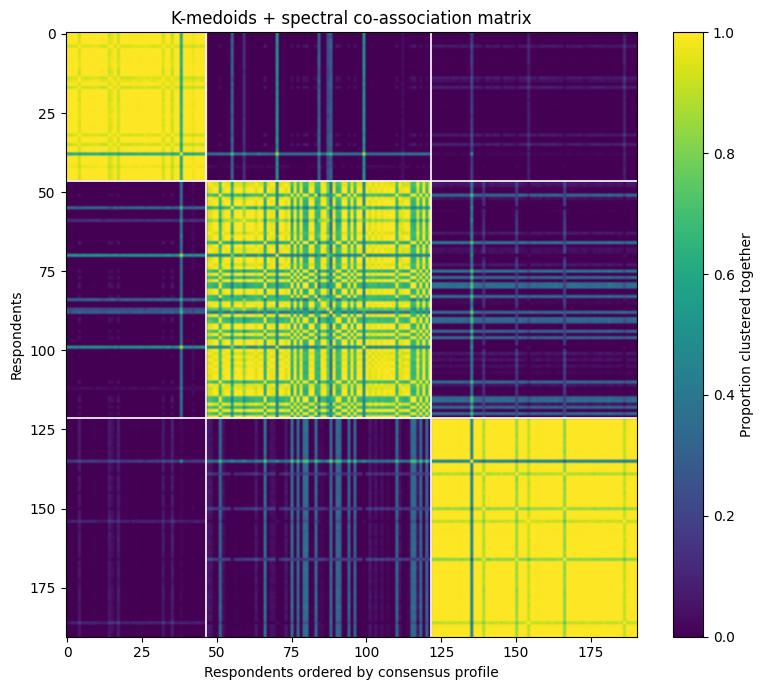

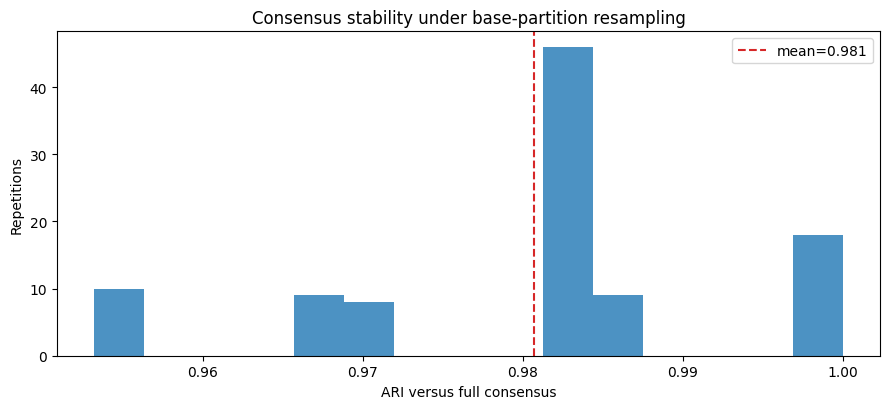

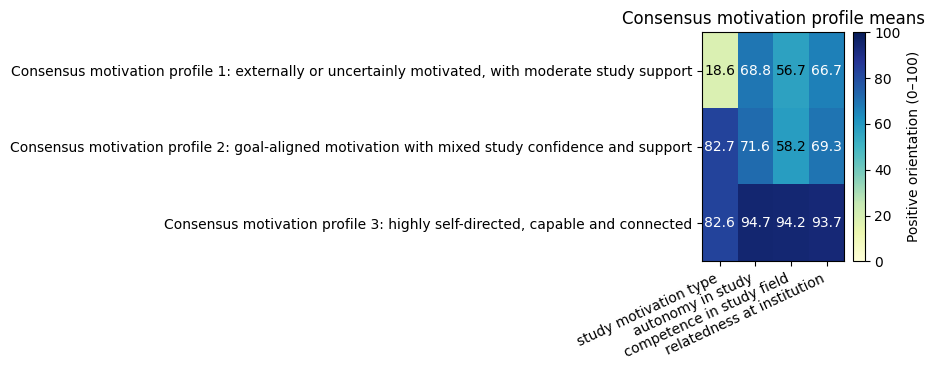

In [9]:
order = np.argsort(profile_id, kind="stable")
fig, ax = plt.subplots(figsize=(8, 7))
heat = ax.imshow(consensus[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1, aspect="auto")
boundaries = np.cumsum(pd.Series(profile_id[order]).value_counts(sort=False).sort_index().to_numpy())[:-1]
for boundary in boundaries:
    ax.axhline(boundary - 0.5, color="white", linewidth=1.2)
    ax.axvline(boundary - 0.5, color="white", linewidth=1.2)
ax.set(title="K-medoids + spectral co-association matrix", xlabel="Respondents ordered by consensus profile", ylabel="Respondents")
fig.colorbar(heat, ax=ax, label="Proportion clustered together")
fig.tight_layout()
fig.savefig(OUT / "motivation_consensus_matrix_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(ensemble_stability["ari_vs_full_consensus"], bins=15, color="tab:blue", alpha=0.8)
ax.axvline(ensemble_stability["ari_vs_full_consensus"].mean(), color="tab:red", linestyle="--",
           label=f"mean={ensemble_stability['ari_vs_full_consensus'].mean():.3f}")
ax.set(title="Consensus stability under base-partition resampling", xlabel="ARI versus full consensus", ylabel="Repetitions")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "motivation_consensus_stability.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
heat = ax.imshow(profile_means.to_numpy(), cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(VARIABLES)), [v.replace("_", " ") for v in VARIABLES], rotation=25, ha="right")
ax.set_yticks(range(K), [profile_names[int(i)] for i in profile_means.index])
for i in range(K):
    for j in range(len(VARIABLES)):
        value = profile_means.iloc[i, j]
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", color="white" if value > 65 else "black")
fig.colorbar(heat, ax=ax, label="Positive orientation (0–100)")
ax.set_title("Consensus motivation profile means")
fig.tight_layout()
fig.savefig(OUT / "motivation_consensus_profile_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Save reproducible outputs

In [10]:
base_partition_diagnostics.to_csv(OUT / "consensus_base_partition_diagnostics.csv", index=False)
assignment.to_csv(OUT / "motivation_consensus_assignments.csv", index=False)
profile_sizes.to_csv(OUT / "motivation_consensus_profile_sizes.csv", index=False)
profile_means.to_csv(OUT / "motivation_consensus_profile_means.csv")
respondent_confidence.to_csv(OUT / "motivation_consensus_respondent_confidence.csv", index=False)
pair_block_consensus.to_csv(OUT / "motivation_consensus_profile_block_strength.csv", index=False)
ensemble_stability.to_csv(OUT / "motivation_consensus_ensemble_stability.csv", index=False)
algorithm_comparison.to_csv(OUT / "motivation_consensus_algorithm_agreement.csv", index=False)
quality_checks.to_csv(OUT / "motivation_consensus_quality_checks.csv", index=False)

consensus_export = pd.DataFrame(consensus, columns=cohort["respondent_id"])
consensus_export.insert(0, "respondent_id", cohort["respondent_id"].to_numpy())
consensus_export.to_csv(OUT / "motivation_consensus_matrix.csv", index=False)

coverage_export = pd.DataFrame(coverage_count, columns=cohort["respondent_id"])
coverage_export.insert(0, "respondent_id", cohort["respondent_id"].to_numpy())
coverage_export.to_csv(OUT / "motivation_consensus_pair_coverage.csv", index=False)

summary = {
    "cohort": {
        "records": int(len(cohort)),
        "branch": "D",
        "routing_source": "translated_final_active_branch",
        "variables": VARIABLES,
    },
    "ensemble": {
        "k": K,
        "algorithms": ["K-medoids on ordinal Gower", "spectral clustering on Gower affinity"],
        "subsamples_per_algorithm": SUBSAMPLE_REPETITIONS,
        "total_base_partitions": ENSEMBLE_PARTITIONS,
        "subsample_fraction": SUBSAMPLE_FRACTION,
        "equal_algorithm_weight": True,
        "final_method": "K-medoids on one minus the co-association matrix",
    },
    "profiles": {
        "sizes": {str(int(r.consensus_profile_id)): int(r.records) for r in profile_sizes.itertuples()},
        "names": {str(k): v for k, v in profile_names.items()},
    },
    "metrics": consensus_metrics,
    "agreement": {
        "ari_vs_full_kmedoids_k3": ari_consensus_kmedoids,
        "ari_vs_full_spectral_k3": ari_consensus_spectral,
        "prior_kmedoids_reproduction_ari": None if prior_reproduction_ari is None else float(prior_reproduction_ari),
    },
    "decision": {
        "primary_checks_passed": primary_pass,
        "checks_passed": int(quality_checks["passed"].sum()),
        "checks_total": int(len(quality_checks)),
        "status": status,
    },
}

with open(OUT / "motivation_consensus_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

print(json.dumps(summary, indent=2))
print("\nSaved files:")
for path in sorted(OUT.iterdir()):
    print(" -", path.name)

{
  "cohort": {
    "records": 191,
    "branch": "D",
    "routing_source": "translated_final_active_branch",
    "variables": [
      "study_motivation_type",
      "autonomy_in_study",
      "competence_in_study_field",
      "relatedness_at_institution"
    ]
  },
  "ensemble": {
    "k": 3,
    "algorithms": [
      "K-medoids on ordinal Gower",
      "spectral clustering on Gower affinity"
    ],
    "subsamples_per_algorithm": 100,
    "total_base_partitions": 200,
    "subsample_fraction": 0.8,
    "equal_algorithm_weight": true,
    "final_method": "K-medoids on one minus the co-association matrix"
  },
  "profiles": {
    "sizes": {
      "1": 47,
      "2": 75,
      "3": 69
    },
    "names": {
      "1": "Consensus motivation profile 1: externally or uncertainly motivated, with moderate study support",
      "2": "Consensus motivation profile 2: goal-aligned motivation with mixed study confidence and support",
      "3": "Consensus motivation profile 3: highly self-direct

## Interpretation guardrails

- Consensus stability measures reproducibility of this specified K-medoids-plus-spectral ensemble; it does not prove naturally discrete psychological types.
- Consensus can average away algorithm disagreement, so agreement with both source methods must be reported.
- Respondents with low consensus margins should not receive strong profile labels.
- The four ordinal variables remain single survey items, and equal spacing between response levels is a modelling assumption.
- If consensus does not improve the predeclared diagnostics, retain the separate algorithm comparison and report motivation as continuous or method-dependent.